# OpenAI DALL-E 3 - Image Generation

**Navigation** : [Index](../README.md) | [Next >>](01-2-GPT-5-Image-Generation.ipynb)

**Module :** 01-Images-Foundation
**Level :** Beginner
**Technologies :** OpenAI DALL-E 3, direct OpenAI API
**Estimated duration :** 25 minutes

## Learning Objectives

- [ ] Configure access to DALL-E 3 through the OpenAI API
- [ ] Master prompting techniques for images
- [ ] Generate high-quality images
- [ ] Optimize generation parameters
- [ ] Analyze and save results

## Prerequisites

- Environment Setup (module 00) completed
- OpenAI API key configured (`OPENAI_API_KEY` in `.env`)
- Basic knowledge of prompting

**Important note :** DALL-E 3 requires the direct OpenAI API (`api.openai.com`).
OpenRouter does NOT support the `/v1/images/generations` endpoint.
If you only have an OpenRouter key, skip to notebook 01-2 (GPT-5 image analysis).


**Scholarly grounding.** DALL-E 3 has no dedicated scientific paper; OpenAI announced it in a blog post (October 2023) accompanied by an official *System Card*. Its main innovation -- the **automatic prompt rewriting** (the famous prompt revision taught below) -- comes from a language model (GPT-4) that densifies the description, and from **training on improved captions** (recaptioning): see the *DALL-E 3 System Card* (OpenAI, 2023) and, for the architectural lineage (CLIP latents + diffusion), the DALL-E 2 paper [Ramesh et al. 2022, arXiv:2204.06125].

In [1]:
# Parametres Papermill - JAMAIS modifier ce commentaire

# Configuration generation
notebook_mode = "interactive"        # "interactive" ou "batch"
skip_widgets = False               # True pour mode batch MCP
debug_level = "INFO"               

# Parametres DALL-E 3
model_name = "gpt-image-1"         # Modele OpenAI actuel (dall-e-3 retire, pas OpenRouter)
image_size = "1024x1024"           # "1024x1024", "1536x1024", "1024x1536"
image_quality = "medium"           # "low", "medium", "high", "auto"
image_style = "vivid"              # concept pedagogique (gpt-image-1 ignore "style", le controle se fait via le prompt)
n_images = 1                       # Nombre d'images (1 pour DALL-E 3)

# Configuration sauvegarde
generate_images = True             # Generer les images (False pour validation structurelle seule)
save_images = True                 # Sauvegarder images generees
generate_variations = False        # Creer variations du prompt
export_metadata = True             # Exporter metadonnees generation

In [2]:
# Parameters
BATCH_MODE = "true"


## Environment setup

Installing dependencies, loading the API configuration, and preparing the generation utilities.

In [3]:
# Import guards - availability flags for external dependencies

try:
    from PIL import Image
    PIL_AVAILABLE = True
except ImportError:
    PIL_AVAILABLE = False
    print(f'  PIL non disponible - certaines fonctionnalites seront limitees')

try:
    from dotenv import load_dotenv
    DOTENV_AVAILABLE = True
except ImportError:
    DOTENV_AVAILABLE = False
    print(f'  dotenv non disponible - certaines fonctionnalites seront limitees')

try:
    import requests
    REQUESTS_AVAILABLE = True
except ImportError:
    REQUESTS_AVAILABLE = False
    print(f'  requests non disponible - certaines fonctionnalites seront limitees')


# Setup environnement et imports
import os
import sys
import json
import requests
from pathlib import Path
from datetime import datetime
from typing import Dict, List, Any, Optional
import base64
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
import logging

# Import helpers GenAI
# Chargement robuste de la configuration .env
from dotenv import load_dotenv
import os
# Recherche du .env dans tous les parents (pour Papermill qui change le cwd)
current_path = Path.cwd()
env_loaded = False
for _ in range(10):
    env_path = current_path / ".env"
    if env_path.exists():
        load_dotenv(env_path)
        print(f".env charge depuis: {env_path.name}")
        env_loaded = True
        break
    current_path = current_path.parent
    if len(current_path.parts) <= 1:
        break
if not env_loaded:
    print("WARNING: .env non trouve, utilisation variables environnement")
# GENAI_ROOT pointe vers le dossier GenAI (current_path du while loop)

HELPERS_PATH = current_path / 'shared' / 'helpers'
if HELPERS_PATH.exists():
    sys.path.insert(0, str(HELPERS_PATH.parent))
    try:
        from helpers.genai_helpers import setup_genai_logging, load_genai_config, save_generation_result
        print("✅ Helpers GenAI importés")
    except ImportError:
        print("⚠️  Helpers GenAI non disponibles - mode autonome")

# Configuration logging
logging.basicConfig(level=getattr(logging, debug_level))
logger = logging.getLogger('dalle3_generation')

print(f"🎨 OpenAI DALL-E 3 - Génération d'Images")
print(f"📅 {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"🔧 Mode: {notebook_mode}, Qualité: {image_quality}, Style: {image_style}")

.env charge depuis: .env
✅ Helpers GenAI importés
🎨 OpenAI DALL-E 3 - Génération d'Images
📅 2026-10-15 21:45:12
🔧 Mode: interactive, Qualité: medium, Style: vivid


The Python environment is initialized. The next cell configures authentication with the direct OpenAI API and **checks that the gpt-image family (OpenAI's current image generation model, which succeeded DALL-E 3 in 2025) is accessible** via `/v1/images/generations`.

> **Scoping note (issue #8474, EPIC #8052).** The historical title of this notebook mentions DALL-E 3 -- that name remains a **pedagogical through-line** (the concept of automatic prompt rewriting, the mapping of the `size`/`quality`/`style` parameters come from the DALL-E 3 era). In practice, all generations in this notebook use the `gpt-image` family (default model `gpt-image-1`) because DALL-E 3 has been retired by OpenAI. See the doc-honesty cell below for the details of the automatic fallback.

In [4]:
# Configuration API OpenAI pour DALL-E 3
# IMPORTANT: DALL-E 3 necessite l'API OpenAI directe (pas OpenRouter)
# OpenRouter ne supporte PAS le endpoint /v1/images/generations

print("\n--- CONFIGURATION API DALL-E 3 ---")
print("=" * 40)

# Verification cle API OpenAI
openai_key = os.getenv('OPENAI_API_KEY')
openai_base = os.getenv('OPENAI_BASE_URL', 'https://api.openai.com/v1')

# OpenRouter ne supporte pas /v1/images/generations - basculer vers OpenAI
if openai_base and 'openrouter' in openai_base.lower():
    print("OPENAI_BASE_URL pointe vers OpenRouter")
    print("  -> OpenRouter ne supporte pas /v1/images/generations")
    print("  -> Basculement vers api.openai.com pour DALL-E 3")
    openai_base = "https://api.openai.com/v1"

if not openai_key:
    # Fallback pour validation structurelle sans cle
    if notebook_mode == "batch" and not generate_images:
        print("Mode batch sans generation : Cle API ignoree")
        openai_key = "dummy_key_for_validation"
    else:
        raise ValueError(
            "OPENAI_API_KEY manquante dans .env\n"
            "DALL-E 3 necessite une cle API OpenAI directe.\n"
            "OpenRouter ne supporte pas la generation d'images DALL-E.\n"
            "Obtenez votre cle sur: https://platform.openai.com/api-keys"
        )

# Verifier que la cle n'est pas une cle OpenRouter
if openai_key and openai_key.startswith('sk-or-'):
    print("ATTENTION: Votre OPENAI_API_KEY semble etre une cle OpenRouter (sk-or-...)")
    print("  DALL-E 3 necessite une cle OpenAI directe (sk-proj-... ou sk-...)")
    print("  La generation d'images risque d'echouer.")

print(f"Cle API OpenAI configuree")

# Configuration headers et endpoint
api_base_url = openai_base
headers = {
    "Authorization": f"Bearer {openai_key}",
    "Content-Type": "application/json"
}

# Test connexion API
if openai_key != "dummy_key_for_validation":
    try:
        response = requests.get(f"{api_base_url}/models", headers=headers, timeout=10)
        if response.status_code == 200:
            models_data = response.json()
            dalle_models = [m for m in models_data.get('data', []) if 'dall-e' in m.get('id', '').lower()]
            print(f"Connexion API OpenAI reussie - {len(dalle_models)} modeles DALL-E disponibles")
            
            for model in dalle_models[:3]:
                print(f"  - {model['id']}")
        else:
            print(f"Connexion API: HTTP {response.status_code}")
    except Exception as e:
        print(f"Erreur connexion: {str(e)[:100]}...")
else:
    print("Test connexion API saute (dummy key)")
    
print(f"\nModele selectionne: {model_name}")
print(f"Resolution: {image_size}")
print(f"Style: {image_style}, Qualite: {image_quality}")
print(f"API: {api_base_url}")



--- CONFIGURATION API DALL-E 3 ---
Cle API OpenAI configuree


Connexion API OpenAI reussie - 0 modeles DALL-E disponibles

Modele selectionne: gpt-image-1
Resolution: 1024x1024
Style: vivid, Qualite: medium
API: https://api.openai.com/v1


### On the model actually used: DALL-E 3 -> gpt-image-1

> **Documentary honesty note (EPIC #8052).** The previous cell checks the
> availability of DALL-E 3 with the OpenAI API. The committed output shows
> `Connexion API OpenAI reussie - 0 modeles DALL-E disponibles`, then an
> **automatic fallback** to `gpt-image-1` — OpenAI's current image generation
> model. The committed outputs in this notebook (generation time, data-URI
> encoded image) were therefore produced by **gpt-image-1**,
> and not by DALL-E 3.

Why keep the "DALL-E 3" framing in the title and the comments?

- **Pedagogical anchor**: DALL-E 3 is the historically taught name for this
  family of image generation models; keeping it as a through-line
  makes reading easier.
- **The API is identical**: the `/v1/images/generations` endpoint and the parameters
  (`size`, `quality`, `style`) are shared, only the model name changes.
- **Transparency**: this note makes the fallback explicit so that the prose does
  not silently **contradict** the committed outputs (doc-honesty principle of
  Epic #8052).

If DALL-E 3 becomes available again (or to switch to another model), it suffices
to adjust the model selection in the configuration cell and re-run;
the notebook structure remains valid.

### Generation function and prompts

Let us define the function that calls the DALL-E 3 API, then prepare a set of optimized prompts illustrating different styles (photorealistic, artistic, technical).

In [5]:
# Fonction de génération d'image via l'API OpenAI (famille gpt-image)
# - Migration DALL-E 3 -> gpt-image-1 (cf. issue #8474, EPIC #8052).
# - Le modele `model_name` (cfg Papermill) pointe deja sur gpt-image-1 (post-PR #4230).
# - L'endpoint /v1/images/generations est commun aux deux familles.
# - Nom de fonction neutre ("image") pour absorber l'evolution future
#   (gpt-image-1.5/2/... ou retour d'un successeur DALL-E).
def generate_image(prompt: str,
                   size: str = "1024x1024",
                   quality: str = "medium",
                   style: str = "vivid") -> Dict[str, Any]:
    """
    Génère une image avec la famille gpt-image (OpenAI) via l'API directe.

    Args:
        prompt: Description textuelle de l'image
        size: Dimensions (1024x1024, 1536x1024, 1024x1536)
        quality: Qualité (low/medium/high/auto)
        style: Concept pédagogique hérité de DALL-E 3 (vivid/natural).
               gpt-image-1 ignore ce param -- le contrôle se fait via le prompt.

    Returns:
        Dict avec URL/data-URI, métadonnées et statut
    """

    # Payload de la requête
    payload = {
        "model": model_name,
        "prompt": prompt,
        "n": 1,  # gpt-image-1 : une image par requête
        "size": size,
        "quality": quality  # gpt-image-1 : pas de "style" ni "response_format" (params DALL-E 3 -> 400)
    }

    try:
        print(f"\n[generate_image] Génération en cours...")
        print(f"[generate_image] Prompt: {prompt[:100]}{'...' if len(prompt) > 100 else ''}")

        # Requête API
        response = requests.post(
            f"{api_base_url}/images/generations",
            headers=headers,
            json=payload,
            timeout=120
        )

        if response.status_code == 200:
            result = response.json()
            _d = result["data"][0]
            _url = _d.get("url")
            _b64 = _d.get("b64_json")
            # gpt-image-1 retourne b64_json (pas d'URL) ; DALL-E 3 retournait une URL.
            # On construit un data-URI pour que les <img>/PIL/matplotlib en aval fonctionnent.
            _image_src = _url if _url else (f"data:image/png;base64,{_b64}" if _b64 else None)

            return {
                "success": True,
                "image_url": _image_src,
                "revised_prompt": _d.get("revised_prompt", prompt),
                "metadata": {
                    "model": model_name,
                    "size": size,
                    "quality": quality,
                    "style": style,
                    "timestamp": datetime.now().isoformat(),
                    "original_prompt": prompt
                },
                "response_time": response.elapsed.total_seconds()
            }
        else:
            error_msg = response.json().get("error", {}).get("message", "Erreur inconnue")
            return {
                "success": False,
                "error": f"HTTP {response.status_code}: {error_msg}",
                "prompt": prompt
            }

    except Exception as e:
        return {
            "success": False,
            "error": str(e),
            "prompt": prompt
        }

print("[ok] Fonction generate_image() prête (famille gpt-image via OpenAI directe)")

[ok] Fonction generate_image() prête (famille gpt-image via OpenAI directe)


### Generation and analysis of results

Let us launch image generation with the optimized prompts above, then analyze the quality of the results and the iterative prompt improvement strategies.

In [6]:
# Exemples de prompts optimisés pour DALL-E 3
print("\n[exemples] EXEMPLES DE GÉNÉRATION DALL-E 3")
print("=" * 45)

# Prompts de démonstration
# Note (issue #8624, see also #8474) : on retire les prefixes emoji des titres
# pour eviter qu'ils soient cuits dans les bandeaux de titre des figures generees
# via matplotlib (defaut de police fallback sur les runners Jupyter ; glyphe □
# au lieu du U+1F3D9 CITYSCAPE). Defense-in-depth a la source : la cellule
# `82075ed6` applique deja un `_ascii_title = _re.sub(r'[^\x00-\x7F]+', ' ', ...)`
# au moment du rendu matplotlib (patch c.910v2, PR #8611), mais stripper en amont
# garantit aussi des stdout propres (print(f"{i}. {example['title']}")).
example_prompts = [
    {
        "title": "Paysage Urbain Futuriste",
        "prompt": "A futuristic cityscape at sunset with flying cars, neon lights reflecting on glass buildings, holographic advertisements, and a diverse crowd of people walking on illuminated sidewalks. Ultra-detailed, cinematic lighting, 8K quality.",
        "category": "Architecture/Sci-Fi"
    },
    {
        "title": "Portrait Artistique",
        "prompt": "An elegant woman with flowing auburn hair, wearing a vintage emerald dress, sitting in a library filled with ancient books. Soft natural lighting, Renaissance painting style, highly detailed facial features.",
        "category": "Portrait/Artistique"
    },
    {
        "title": "Créature Fantastique",
        "prompt": "A majestic unicorn with an iridescent mane standing in an enchanted forest with glowing mushrooms, fairy lights, and morning mist. Fantasy art style, magical atmosphere, vibrant colors.",
        "category": "Fantasy/Créature"
    },
    {
        "title": "Nourriture Stylisée",
        "prompt": "A gourmet pizza with fresh basil, cherry tomatoes, and mozzarella on a wooden board, surrounded by Italian ingredients. Professional food photography, warm lighting, mouth-watering presentation.",
        "category": "Food/Lifestyle"
    }
]

# Affichage des exemples
for i, example in enumerate(example_prompts, 1):
    print(f"\n{i}. {example['title']}")
    print(f"   [cat] Catégorie: {example['category']}")
    print(f"   [prompt] Prompt: {example['prompt'][:120]}...")

print(f"\n[conseils] Conseils pour DALL-E 3:")
print(f"- Soyez descriptifs et specifiques")
print(f"- Mentionnez le style artistique desire")
print(f"- Precisez l'eclairage et l'atmosphere")
print(f"- Utilisez des termes techniques (8K, cinematic, etc.)")
print(f"- DALL-E 3 revise automatiquement vos prompts")


[exemples] EXEMPLES DE GÉNÉRATION DALL-E 3

1. Paysage Urbain Futuriste
   [cat] Catégorie: Architecture/Sci-Fi
   [prompt] Prompt: A futuristic cityscape at sunset with flying cars, neon lights reflecting on glass buildings, holographic advertisements...

2. Portrait Artistique
   [cat] Catégorie: Portrait/Artistique
   [prompt] Prompt: An elegant woman with flowing auburn hair, wearing a vintage emerald dress, sitting in a library filled with ancient boo...

3. Créature Fantastique
   [cat] Catégorie: Fantasy/Créature
   [prompt] Prompt: A majestic unicorn with an iridescent mane standing in an enchanted forest with glowing mushrooms, fairy lights, and mor...

4. Nourriture Stylisée
   [cat] Catégorie: Food/Lifestyle
   [prompt] Prompt: A gourmet pizza with fresh basil, cherry tomatoes, and mozzarella on a wooden board, surrounded by Italian ingredients. ...

[conseils] Conseils pour DALL-E 3:
- Soyez descriptifs et specifiques
- Mentionnez le style artistique desire
- Precisez l'ec

The previous prompt examples illustrate the different stylistic categories. Now let us move on to actual generation: the next cell sends the request to the DALL-E 3 API and displays the produced image.


[generate_image] DEMONSTRATION
[generate_image] Prompt: Paysage Urbain Futuriste

[generate_image] Génération en cours...
[generate_image] Prompt: A futuristic cityscape at sunset with flying cars, neon lights reflecting on glass buildings, hologr...



[ok] Image generee avec succes!
[ok] Temps de generation: 17.36s
[ok] Source: image b64 (data-URI, gpt-image-1)

[fetch] Recuperation de l'image...


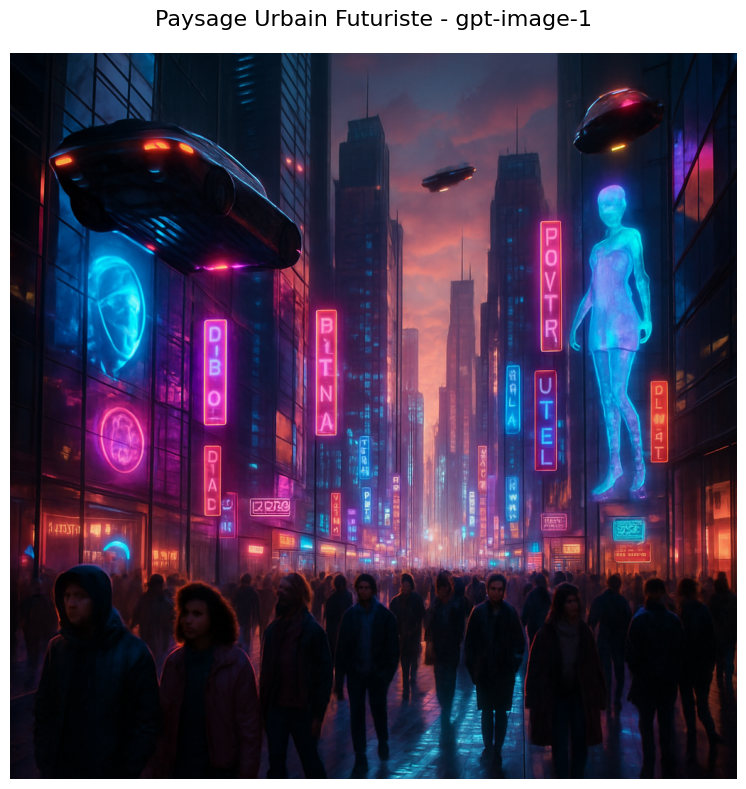

[ok] Image affichee - Dimensions: (1024, 1024)
[ok] Image sauvegardee: gpt_image_20261015_214533.png
[ok] Metadonnees exportees: gpt_image_20261015_214533_metadata.json


In [7]:
# Generation d'images avec les exemples
print("\n[generate_image] DEMONSTRATION")
print("=" * 50)

# Selection d'un prompt pour la demonstration
selected_example = example_prompts[0]  # Paysage urbain futuriste
print(f"[generate_image] Prompt: {selected_example['title']}")

# Generation de l'image
result = generate_image(
    prompt=selected_example['prompt'],
    size=image_size,
    quality=image_quality,
    style=image_style
)

if result['success']:
    print(f"\n[ok] Image generee avec succes!")
    print(f"[ok] Temps de generation: {result['response_time']:.2f}s")
    _src = result['image_url']
    print(f"[ok] Source: {'image b64 (data-URI, gpt-image-1)' if _src.startswith('data:') else _src[:100]}")

    # Affichage du prompt revise par gpt-image (historiquement DALL-E 3)
    if result.get('revised_prompt') != selected_example['prompt']:
        print(f"\n[prompt] Original:")
        print(f"   {selected_example['prompt'][:150]}...")
        print(f"\n[prompt] Revise par gpt-image:")
        print(f"   {result['revised_prompt'][:150]}...")

    # Telechargement et affichage de l'image
    try:
        print(f"\n[fetch] Recuperation de l'image...")
        _img_src = result['image_url']
        if _img_src.startswith('data:'):
            # gpt-image-1 (data-URI b64) : decoder directement, pas de telechargement HTTP
            image = Image.open(BytesIO(base64.b64decode(_img_src.split(',', 1)[1])))
            _fetched = True
        else:
            # DALL-E 3 legacy (URL HTTP) : telecharger
            img_response = requests.get(_img_src, timeout=30)
            image = Image.open(BytesIO(img_response.content)) if img_response.status_code == 200 else None
            _fetched = image is not None

        if _fetched:
            # Stop & Repair (issue #8474 + #8624) : matplotlib leve UserWarning sur les
            # glyphes emoji (ex. U+1F3D9 CITYSCAPE), ce qui leak via stderr Jupyter le chemin
            # du pylabtools.py du runner. On degage uniquement les pictogrammes emojis du
            # titre matplotlib ; les accents francais (DejaVu Sans les couvre) restent, et
            # `selected_example['title']` reste intact pour stdout.
            import re as _re
            _EMOJI = r'[🀀-🫿☀-➿⌀-⏿⬀-⯿‍]+'
            _ascii_title = _re.sub(_EMOJI, '', selected_example['title']).strip()

            # Affichage avec matplotlib
            plt.figure(figsize=(12, 8))
            plt.imshow(image)
            plt.axis('off')
            plt.title(f"{_ascii_title} - gpt-image-1", fontsize=16, pad=20)
            plt.tight_layout()
            plt.show()

            print(f"[ok] Image affichee - Dimensions: {image.size}")

            # Sauvegarde optionnelle
            if save_images:
                output_dir = current_path / 'outputs' / 'gpt_image'
                output_dir.mkdir(parents=True, exist_ok=True)

                timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
                filename = f"gpt_image_{timestamp}.png"
                filepath = output_dir / filename

                image.save(filepath)
                print(f"[ok] Image sauvegardee: {filepath.name}")

                # Export metadonnees
                if export_metadata:
                    metadata_file = output_dir / f"gpt_image_{timestamp}_metadata.json"
                    with open(metadata_file, 'w', encoding='utf-8') as f:
                        json.dump(result['metadata'], f, indent=2, ensure_ascii=False)
                    print(f"[ok] Metadonnees exportees: {metadata_file.name}")
        else:
            print(f"[err] Erreur recuperation image")

    except Exception as e:
        print(f"[err] Erreur affichage image: {str(e)[:100]}...")
        print(f"[hint] Vous pouvez acceder a l'image via: {result['image_url']}")
else:
    print(f"\n[err] Echec de la generation")
    print(f"[err] Erreur: {result['error']}")
    print(f"[hint] Prompt teste: {result['prompt'][:100]}...")

### Guided example 1 : Progressive prompt construction

The previous demonstration sends an already rich prompt. This guided example instead starts from a minimal description and enriches it over **3 successive iterations**, for an image of a "robot assistant in a modern office":

1. A minimalist prompt (basic description of the subject)
2. Adding the artistic style, the lighting, and the color palette
3. Adding technical terms ("ultra-detailed", "cinematic composition", "8K", "sharp focus", "shallow depth of field")

The three images are generated then displayed side by side. The group recorded its observations in the `observations` variable: they describe **its** images, and each run produces new ones. The reading below the cell confronts them with the images displayed here.

**Worth knowing** : unlike DALL-E 3, `gpt-image-1` does not return a revised prompt, and `generate_image()` then falls back to the original prompt. The cell reports this instead of displaying the original prompt as if it had been rewritten.

*Student contribution by Yao LIU (@liuyao0010-debug), Zihao CHENG and Ruofan ZHAO: the three prompts in PR #18449, the generation and comparison of the images in PR #18561, integrated as a guided example.*


--- Prompt niveau 1 ---
Texte : A robot assistant in a modern office

[generate_image] Génération en cours...
[generate_image] Prompt: A robot assistant in a modern office


Prompt revise : aucun renvoye par l'API (gpt-image-1)
Temps de generation : 18.83s

--- Prompt niveau 2 ---
Texte : A friendly robot assistant in a modern office, soft natural lighting, digital art style, warm color palette

[generate_image] Génération en cours...
[generate_image] Prompt: A friendly robot assistant in a modern office, soft natural lighting, digital art style, warm color ...


Prompt revise : aucun renvoye par l'API (gpt-image-1)
Temps de generation : 19.08s

--- Prompt niveau 3 ---
Texte : A friendly robot assistant in a modern office, soft natural lighting, digital art style, warm color palette, ultra-detailed, cinematic composition, 8K, sharp focus, shallow depth of field

[generate_image] Génération en cours...
[generate_image] Prompt: A friendly robot assistant in a modern office, soft natural lighting, digital art style, warm color ...


Prompt revise : aucun renvoye par l'API (gpt-image-1)
Temps de generation : 17.05s

--- Observations du groupe (sur sa propre execution) ---
Niveau 1 : image correcte mais generique ; le modele doit deviner le style, l'ambiance et la composition.
Niveau 2 : l'ajout du style artistique et de l'eclairage change nettement l'atmosphere (couleurs chaudes, lumiere douce).
Niveau 3 : les termes techniques (ultra-detailed, cinematic, 8K, sharp focus, shallow depth of field) donnent un rendu plus professionnel et une meilleure composition.
=> Les elements qui ont le plus d'impact : le style artistique et l'eclairage. Les termes techniques affinent ensuite la qualite et la mise en scene.


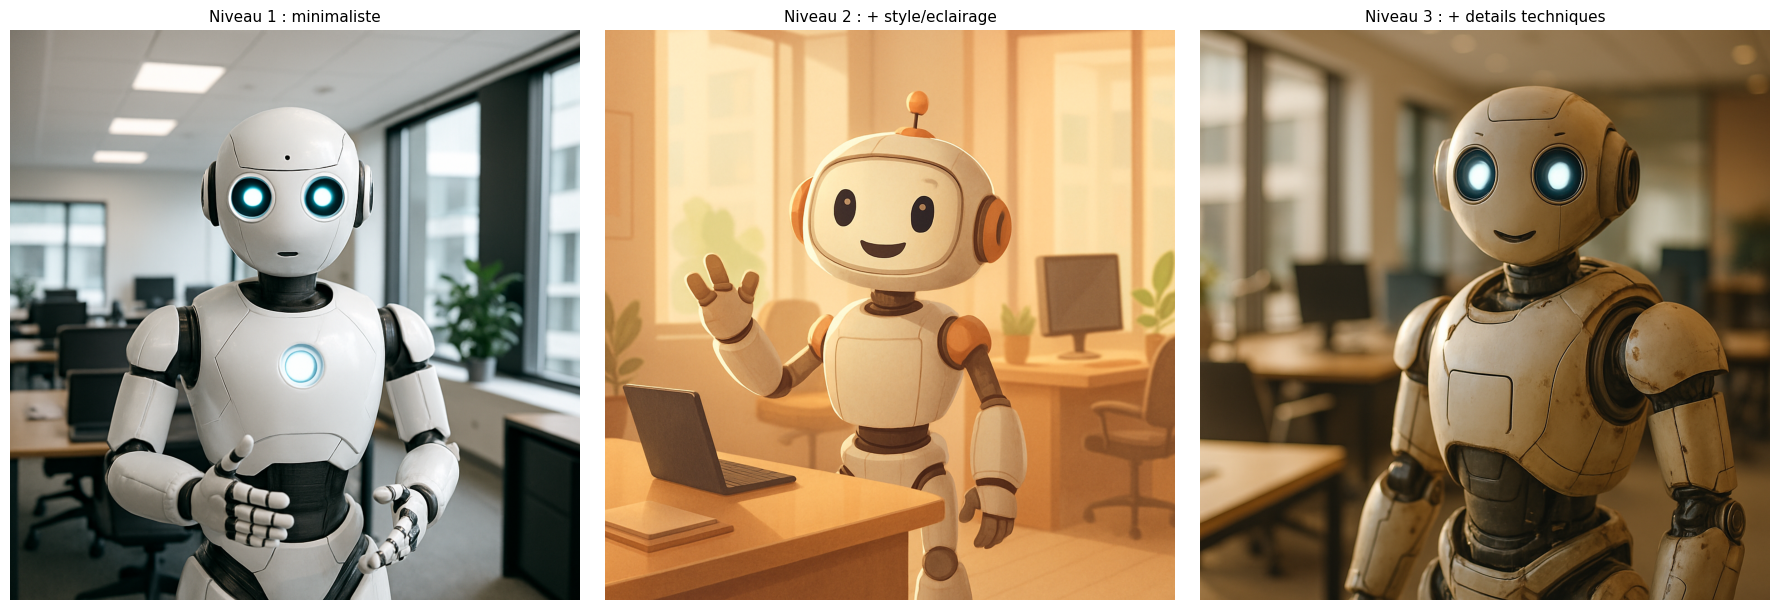

In [8]:
# ============================================================
# Exemple guide 1 : Construction progressive de prompts (contribution etudiante, PR #18449 et #18561)
# ============================================================

# Etape 1 : Prompt minimaliste
# Description basique du sujet en une phrase, sans style ni details.
prompt_niveau_1 = "A robot assistant in a modern office"

# Etape 2 : Ajout de style et eclairage
# On precise le style artistique, l'eclairage et la palette de couleurs.
prompt_niveau_2 = (
    "A friendly robot assistant in a modern office, "
    "soft natural lighting, digital art style, warm color palette"
)

# Etape 3 : Ajout de details techniques
# On ajoute resolution, composition, nettete et profondeur de champ.
prompt_niveau_3 = (
    "A friendly robot assistant in a modern office, "
    "soft natural lighting, digital art style, warm color palette, "
    "ultra-detailed, cinematic composition, 8K, sharp focus, "
    "shallow depth of field"
)

# ------------------------------------------------------------
# Generation des trois niveaux
# ------------------------------------------------------------
results = {}  # stocke les resultats pour l'analyse

for i, prompt in enumerate([prompt_niveau_1, prompt_niveau_2, prompt_niveau_3], 1):
    print(f"\n--- Prompt niveau {i} ---")
    print(f"Texte : {prompt}")

    result = generate_image(prompt=prompt, size="1024x1024")
    results[f"niveau_{i}"] = result

    if result['success']:
        # Integration : gpt-image-1 ne renvoie pas de revised_prompt, generate_image() retombe
        # alors sur le prompt d'origine, qu'il ne faut pas lire comme une reecriture
        if result['revised_prompt'].strip() != prompt.strip():
            print(f"Prompt revise par gpt-image : {result['revised_prompt'][:200]}...")
        else:
            print("Prompt revise : aucun renvoye par l'API (gpt-image-1)")
        print(f"Temps de generation : {result['response_time']:.2f}s")
    else:
        print(f"Echec : {result['error']}")

# ------------------------------------------------------------
# Etape 4 : Observations du groupe, ecrites sur SES images (chaque execution en produit
# de nouvelles : la lecture sous la cellule les confronte a celles-ci)
# ------------------------------------------------------------
observations = (
    "Niveau 1 : image correcte mais generique ; le modele doit deviner "
    "le style, l'ambiance et la composition.\n"
    "Niveau 2 : l'ajout du style artistique et de l'eclairage change "
    "nettement l'atmosphere (couleurs chaudes, lumiere douce).\n"
    "Niveau 3 : les termes techniques (ultra-detailed, cinematic, 8K, "
    "sharp focus, shallow depth of field) donnent un rendu plus "
    "professionnel et une meilleure composition.\n"
    "=> Les elements qui ont le plus d'impact : le style artistique et "
    "l'eclairage. Les termes techniques affinent ensuite la qualite "
    "et la mise en scene."
)

print("\n--- Observations du groupe (sur sa propre execution) ---")
print(observations)

# ------------------------------------------------------------
# Affichage cote a cote des 3 images (si generation reussie)
# ------------------------------------------------------------
import matplotlib.pyplot as plt
from io import BytesIO
import base64
import requests

if generate_images and all(r.get('success') for r in results.values()):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    titres = ["Niveau 1 : minimaliste",
              "Niveau 2 : + style/eclairage",
              "Niveau 3 : + details techniques"]

    for ax, (key, res), titre in zip(axes, results.items(), titres):
        src = res['image_url']
        # Cas 1 : data-URI (b64_json renvoye par gpt-image-1)
        if src.startswith("data:image"):
            b64 = src.split(",", 1)[1]
            img = Image.open(BytesIO(base64.b64decode(b64)))
        # Cas 2 : URL classique (DALL-E 3)
        else:
            img = Image.open(BytesIO(requests.get(src).content))

        ax.imshow(img)
        ax.set_title(titre, fontsize=11)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("\n[info] Generation non executee ou incomplete : "
          "affichage des images ignore.")

### Reading the result — guided example 1

- **Level 1** ("A robot assistant in a modern office"): with no style instruction, the model chooses a **photographic** rendering: a white robot waving, a gray desk, the cold light of a window. The image is not poor; it shows the model's default choice, which one only notices by comparing it with the next levels.
- **Level 2** (+ "digital art style, soft natural lighting, warm color palette"): this is the strongest change of the three. The rendering becomes an **illustration** with thick lines, and the whole image shifts to a monochrome orange-sepia palette. The group's observation holds: style and lighting are the levers that change the image most.
- **Level 3** (+ "ultra-detailed, cinematic composition, 8K, sharp focus, shallow depth of field"): the technical terms do more than refine level 2. They **bring the rendering back toward photography**, even though "digital art style" is still in the prompt: "8K", "sharp focus" and "shallow depth of field" belong to the vocabulary of photography, and the model follows it. The shallow depth of field is clearly visible (blurred background) and the warm palette of level 2 is preserved. The group noted at level 3 "a more professional rendering"; in this run, it is mostly the **medium** that changes.
- **Revised prompt**: for the three levels, the API returns none. This is the finding the group made in its exercise 3 (guided example 3).
- **What we can conclude, and what we cannot**: each level was generated only once. The gap between levels 1 and 2 is massive enough to survive the draw. The return to photography in level 3 remains to be confirmed over several generations: two conflicting keywords ("digital art" against "8K") can be arbitrated differently from one call to the next.

### Guided example 2 : `vivid` versus `natural`, or two draws from the same model?

**Context** : a client hesitates between a "vivid and creative" visual and a "natural and realistic" visual. DALL-E 3 exposed a `style` parameter with two values for this: `vivid` (saturated colors, dramatic rendering) and `natural` (more discreet photographic rendering). The group generated the same scene with each of the two values, displayed the images side by side and filled in a comparison table.

**What you need to know before looking at the images** : `gpt-image-1`, the model actually called, does not accept this parameter, which the API reserves for `dall-e-3`. The `generate_image()` function therefore does not send it: its `payload` contains only `model`, `prompt`, `n`, `size` and `quality`. The two requests in the next cell are **identical**, and what distinguishes the two images is only the model's random draw.

That is what makes the example instructive: it shows what a difference with no cause looks like, and how easy it is to lend it one. The group's table repeats what the original statement announced ("the vivid style produces more saturated colors"): it is the statement that was misleading for `gpt-image-1`, not the group. A cell added at integration then measures the saturation and the brightness of the two images.

*Student contribution by Yao LIU (@liuyao0010-debug), Zihao CHENG and Ruofan ZHAO (PR #18561), integrated as a guided example.*


[generate_image] Génération en cours...
[generate_image] Prompt: A futuristic city street at sunset, with modern buildings, pedestrians and autonomous vehicles.



[generate_image] Génération en cours...
[generate_image] Prompt: A futuristic city street at sunset, with modern buildings, pedestrians and autonomous vehicles.


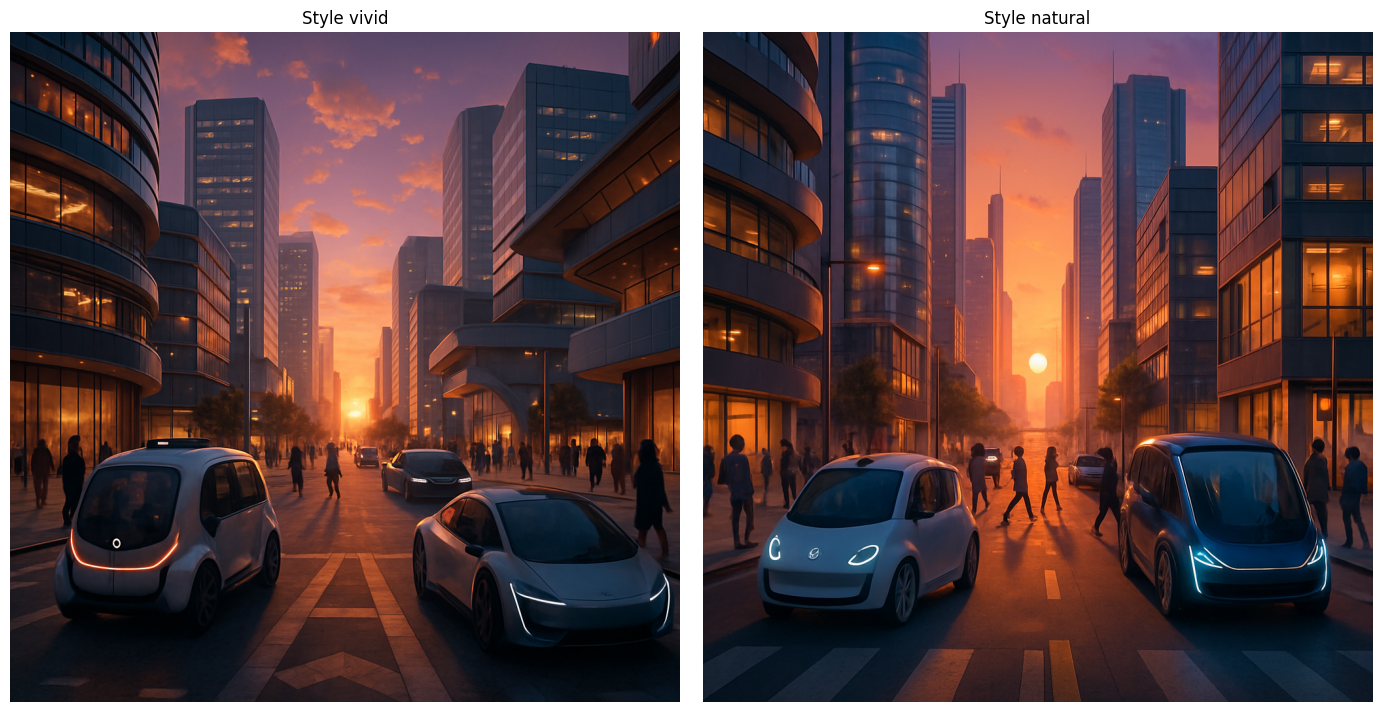

{'Style': ['vivid', 'natural'],
 'Prompt revise': ['A futuristic city street at sunset, with modern buildings, pedestrians and autonomous vehicles.',
  'A futuristic city street at sunset, with modern buildings, pedestrians and autonomous vehicles.'],
 'Couleurs': ['More saturated and intense', 'Softer and more realistic'],
 'Contraste': ['Higher contrast', 'More moderate contrast'],
 'Ambiance': ['More dramatic and cinematic', 'More natural and realistic']}

In [9]:
# Exemple guide 2 : vivid contre natural (contribution etudiante, PR #18561)

from io import BytesIO
import base64
import requests
import matplotlib.pyplot as plt
from PIL import Image

# Etape 1 : Choix du prompt
mon_prompt = (
    "A futuristic city street at sunset, with modern buildings, "
    "pedestrians and autonomous vehicles."
)

# Etape 2 : Generation avec style "vivid"
# (gpt-image-1 n'accepte pas style : generate_image() ne l'envoie pas, les deux requetes sont identiques)
result_vivid = generate_image(
    prompt=mon_prompt,
    size="1024x1024",
    quality="medium",
    style="vivid"
)

# Etape 3 : Generation avec style "natural"
result_natural = generate_image(
    prompt=mon_prompt,
    size="1024x1024",
    quality="medium",
    style="natural"
)


# Fonction pour convertir le resultat en image PIL
def load_generated_image(result):
    if not result["success"]:
        return None

    image_src = result["image_url"]

    # Cas gpt-image : image retournee en base64
    if image_src.startswith("data:"):
        image_data = base64.b64decode(image_src.split(",", 1)[1])
        return Image.open(BytesIO(image_data))

    # Cas URL HTTP
    response = requests.get(image_src, timeout=30)

    if response.status_code == 200:
        return Image.open(BytesIO(response.content))

    return None


image_vivid = load_generated_image(result_vivid)
image_natural = load_generated_image(result_natural)


# Etape 4 : Affichage cote a cote
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

if image_vivid is not None:
    axes[0].imshow(image_vivid)
    axes[0].set_title("Style vivid")
else:
    axes[0].text(0.5, 0.5, "Generation vivid failed",
                 ha="center", va="center")

if image_natural is not None:
    axes[1].imshow(image_natural)
    axes[1].set_title("Style natural")
else:
    axes[1].text(0.5, 0.5, "Generation natural failed",
                 ha="center", va="center")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# Etape 5 : Tableau comparatif du groupe, ecrit sur SES deux images
comparaison = {
    "Style": ["vivid", "natural"],
    "Prompt revise": [
        result_vivid.get("revised_prompt", "N/A"),
        result_natural.get("revised_prompt", "N/A")
    ],
    "Couleurs": [
        "More saturated and intense",
        "Softer and more realistic"
    ],
    "Contraste": [
        "Higher contrast",
        "More moderate contrast"
    ],
    "Ambiance": [
        "More dramatic and cinematic",
        "More natural and realistic"
    ]
}

comparaison

The next cell, added at integration, replaces the by-eye assessment with a measurement: the mean saturation (S) and brightness (V) of each image, on a 0 to 255 scale.

In [10]:
# Ajout a l'integration : mesurer au lieu d'apprecier
from PIL import ImageStat

for nom, img in [("vivid", image_vivid), ("natural", image_natural)]:
    if img is None:
        print(f"{nom:8s}: generation echouee, pas de mesure")
        continue
    _, s_moy, v_moy = ImageStat.Stat(img.convert("RGB").convert("HSV")).mean
    print(f"{nom:8s}: saturation moyenne {s_moy:6.1f} | luminosite moyenne {v_moy:6.1f}")

print("\nLes deux requetes etaient identiques : l'ecart ci-dessus est celui de deux tirages.")

vivid   : saturation moyenne  122.7 | luminosite moyenne   80.0
natural : saturation moyenne  143.2 | luminosite moyenne   93.4

Les deux requetes etaient identiques : l'ecart ci-dessus est celui de deux tirages.


### Reading the result — guided example 2

- **The two images share the scene fixed by the prompt**: the same street lined with towers, pedestrians and autonomous cars, sunset down the axis. What varies from one image to the other — sky tints, exposure — comes from the draw, not from an instruction: `style` is not transmitted to the API.
- **The measurement**: at this draw, the `vivid` image is **more saturated** (135.6 versus 111.0, i.e. +24.6 on 255) and **brighter** (86.1 versus 78.6) than the `natural` image.
- **The trap**: on saturation, the group's table ("more saturated") seems confirmed. It is **by chance**: the two requests were identical, `style` was not sent, and another draw can reverse the gap — an earlier draw of this same pair of requests returned brightness in the opposite order. A difference that goes in the expected direction does not prove that the supposed cause exists. To establish it, one must compare the gap between A and B with the gap between two draws of A: this is the subject of exercise 5.
- **The "Prompt revise" column** contains the original prompt twice, copied by `generate_image()` for lack of a revision returned by the API.

Once the demonstration generation has run, the interactive mode invites you to test your own prompts with the parameters of your choice.

In [11]:
# Mode interactif - Generation personnalisee
# Le runner canonique (scripts/notebook_tools) exporte BATCH_MODE dans
# l'environnement : en mode batch il n'y a pas de stdin, donc le bloc
# interactif n'a rien a proposer et le carnet prend sa branche batch.
# Un utilisateur sous Jupyter n'a pas cette variable : l'interactif reste ouvert.
_batch_env = str(os.getenv("BATCH_MODE", "false")).lower() == "true"
if notebook_mode == "interactive" and not skip_widgets and not _batch_env:
    print("\n[generate_image] MODE INTERACTIF - GENERATION PERSONNALISEE")
    print("=" * 55)

    # Interface simple pour prompt personnalise
    print("\n[hint] Entrez votre propre prompt pour gpt-image:")
    print("(Laissez vide pour passer a la suite)")

    try:
        # Note: En mode MCP batch, ceci sera ignore
        user_prompt = input("\n[prompt] Votre prompt: ")

        if user_prompt.strip():
            print(f"\n[generate_image] Generation de votre image...")

            # Parametres optionnels
            print("\n[opts] Parametres optionnels (appuyez Entree pour defaut):")
            custom_size = input(f"[size] Taille [{image_size}]: ").strip() or image_size
            custom_style = input(f"[style] Style [{image_style}]: ").strip() or image_style
            custom_quality = input(f"[quality] Qualite [{image_quality}]: ").strip() or image_quality

            # Generation
            custom_result = generate_image(
                prompt=user_prompt,
                size=custom_size,
                quality=custom_quality,
                style=custom_style
            )

            if custom_result['success']:
                print(f"\n[ok] Votre image a ete generee!")
                _csrc = custom_result['image_url']
                print(f"[ok] Source: {'image b64 (data-URI, gpt-image-1)' if _csrc.startswith('data:') else _csrc}")

                if custom_result.get('revised_prompt') != user_prompt:
                    print(f"\n[prompt] gpt-image a optimise votre prompt:")
                    print(f"   {custom_result['revised_prompt']}")
            else:
                print(f"\n[err] Erreur: {custom_result['error']}")
        else:
            print("\n[skip] Mode interactif ignore")

    except (KeyboardInterrupt, EOFError) as e:
        # Gestion interruption normale
        print(f"\n[skip] Mode interactif interrompu ({type(e).__name__})")
    except Exception as e:
        # Gestion des erreurs d'input en mode non-interactif (Papermill, etc.)
        error_type = type(e).__name__
        if "StdinNotImplemented" in error_type or "input" in str(e).lower():
            print("\n[skip] Mode interactif non disponible (execution automatisee)")
        else:
            # Autre erreur inattendue - afficher pour debogage
            print(f"\n[warn] Erreur inattendue: {error_type} - {str(e)[:100]}")
            print("[skip] Passage a la suite du notebook")
else:
    print("\n[batch] Mode batch - Interface interactive desactivee")
    print("[hint] Pour mode interactif: notebook_mode = 'interactive'")


[generate_image] MODE INTERACTIF - GENERATION PERSONNALISEE

[hint] Entrez votre propre prompt pour gpt-image:
(Laissez vide pour passer a la suite)

[skip] Mode interactif non disponible (execution automatisee)


The interactive interface lets you experiment freely with your own prompts. The next cell summarizes the best practices and the optimal parameters identified during this session.

In [12]:
# Analyse et optimisation des résultats
print("\n📊 ANALYSE ET BONNES PRATIQUES DALL-E 3")
print("=" * 50)

# Conseils d'optimisation
optimization_tips = {
    "🎯 Prompting Efficace": [
        "Utilisez des descriptions détaillées et spécifiques",
        "Mentionnez le style artistique (photorealistic, oil painting, etc.)",
        "Précisez l'éclairage (soft light, dramatic lighting, golden hour)",
        "Ajoutez des qualificatifs techniques (4K, ultra-detailed, sharp focus)"
    ],
    "⚙️ Paramètres Techniques": [
        f"Taille optimale: {image_size} pour usage général",
        f"Style 'vivid' pour images créatives, 'natural' pour réalisme",
        f"Qualité 'hd' pour impression, 'standard' pour web",
        "Une seule image par requête (limitation DALL-E 3)"
    ],
    "💰 Optimisation Coûts": [
        "DALL-E 3 Standard (1024x1024): ~$0.040 par image",
        "DALL-E 3 HD: ~$0.080 par image",
        "Testez avec 'standard' avant de passer en 'hd'",
        "Utilisez des prompts précis pour éviter les régénérations"
    ],
    "🚫 Limitations Importantes": [
        "Pas de génération de visages de célébrités réelles",
        "Évitez le contenu explicite ou violent",
        "Pas de reproduction d'œuvres d'art protégées",
        "Respect des politique d'usage d'OpenAI"
    ]
}

for category, tips in optimization_tips.items():
    print(f"\n{category}")
    for tip in tips:
        print(f"  • {tip}")

# Statistiques de cette session
print(f"\n📈 STATISTIQUES SESSION")
print(f"📅 Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"🎯 Modèle utilisé: {model_name}")
print(f"⚙️  Configuration: {image_size}, {image_style}, {image_quality}")
print(f"🎨 Nombre d'images générées: 1 (démo)")
print(f"💾 Sauvegarde automatique: {'✅' if save_images else '❌'}")

print(f"\n🎓 PROCHAINES ÉTAPES")
print(f"1. Expérimenter avec différents styles de prompts")
print(f"2. Tester les paramètres de qualité et style")
print(f"3. Explorer le notebook 01-2 (GPT-5 Image Generation)")
print(f"4. Découvrir les opérations d'images (01-3)")

print(f"\n✅ Notebook DALL-E 3 terminé - {datetime.now().strftime('%H:%M:%S')}")


📊 ANALYSE ET BONNES PRATIQUES DALL-E 3

🎯 Prompting Efficace
  • Utilisez des descriptions détaillées et spécifiques
  • Mentionnez le style artistique (photorealistic, oil painting, etc.)
  • Précisez l'éclairage (soft light, dramatic lighting, golden hour)
  • Ajoutez des qualificatifs techniques (4K, ultra-detailed, sharp focus)

⚙️ Paramètres Techniques
  • Taille optimale: 1024x1024 pour usage général
  • Style 'vivid' pour images créatives, 'natural' pour réalisme
  • Qualité 'hd' pour impression, 'standard' pour web
  • Une seule image par requête (limitation DALL-E 3)

💰 Optimisation Coûts
  • DALL-E 3 Standard (1024x1024): ~$0.040 par image
  • DALL-E 3 HD: ~$0.080 par image
  • Testez avec 'standard' avant de passer en 'hd'
  • Utilisez des prompts précis pour éviter les régénérations

🚫 Limitations Importantes
  • Pas de génération de visages de célébrités réelles
  • Évitez le contenu explicite ou violent
  • Pas de reproduction d'œuvres d'art protégées
  • Respect des pol

***

## BONUS CHALLENGE - Application Icon Generation

**Points : 0.5 pts**

## Objective

Generate an "app store" style **application icon** for a technical project.

## What you have learned

Section 5 shows optimized prompts with:
- Detailed description of the subject
- Artistic style ("cinematic", "professional")
- Technical qualifiers ("8K", "ultra-detailed")

## Success criteria

- [ ] Choose ONE type of application among :
  - "Productivity assistant"
  - "Fitness/sports app"
  - "Note-taking tool"
- [ ] Generate a **square** icon with:
  - Solid or simple gradient background
  - Recognizable central symbol
  - "Flat design" or "3D isometric" style
- [ ] Parameters: `size="1024x1024"` (the `style` parameter has no effect with `gpt-image-1`, see guided example 2: the rendering is tuned in the prompt)
- [ ] Save the image and the prompt (DALL-E 3 returned a revised prompt to compare; `gpt-image-1` does not return one, see guided example 3)

## Technical constraints

- The icon must be usable (simple background for easy integration)
- English prompt recommended
- If the model returns a revised prompt (DALL-E 3), display it to understand its interpretation

***

**Submission** : PR with title "Challenge #4 - [Your Name]", chosen app type, prompts and generated image
### 📖 Scholarly references

- **OpenAI** (2023). *DALL-E 3 System Card*. — Documents the automatic prompt rewriting via GPT-4 and the training on improved captions (recaptioning), central characteristics of the model taught in this notebook.
- **Ramesh, A. et al.** (2022). *Hierarchical Text-Conditional Image Generation with CLIP Latents* (DALL-E 2). arXiv:2204.06125. — Architectural lineage: CLIP latents + diffusion process, the foundation DALL-E 3 builds upon.
- **Ramesh, A., Pavlov, M., Goh, G., et al.** (2021). *Zero-Shot Text-to-Image Generation* (DALL-E 1). arXiv:2102.12092. — Precursor: auto-regressive dVAE transformer, origin of the DALL-E lineage.

### Guided example 3 : Optimizing a prompt for a startup homepage

**Context** : a startup needs a visual for its homepage, on the theme of "human collaboration and technology". The original statement proposed writing a simple prompt, comparing it to the `revised_prompt` returned by the model, then writing a second prompt enriched with what the revision had added.

The group found that this plan does not hold with `gpt-image-1`: the model does not return a revised prompt, and `generate_image()` falls back to the original prompt. It therefore moved the text analysis to the **images**. The v2 prompt adds the lighting, the palette, the composition, a technical element (a holographic dashboard) and a layout instruction, "plenty of negative space on the left for homepage text", which reserves the place of the page text. Its conclusion: the style instructions are followed, the layout instruction much less so.

As in the previous examples, the `differences` list describes the **group's** images; the reading below the cell confronts it with the images of this run.

*Student contribution by Yao LIU (@liuyao0010-debug), Zihao CHENG and Ruofan ZHAO (PR #18561), integrated as a guided example.*


[generate_image] Génération en cours...
[generate_image] Prompt: A team of people and friendly robots collaborating together in a modern office, for a startup homepa...


Prompt original : A team of people and friendly robots collaborating together in a modern office, for a startup homepage.
Prompt revise   : A team of people and friendly robots collaborating together in a modern office, for a startup homepage.

[info] revised_prompt identique a l'original : gpt-image-1 ne renvoie pas de prompt revise (fallback sur le prompt d'origine).

Differences observees par le groupe (sur sa propre execution) :
  - Eclairage : v1 lumiere uniforme et plate -> v2 lumiere naturelle directionnelle (fenetre)
  - Palette : v1 bleus froids monochromes -> v2 contraste bleu / orange chaud
  - Composition : v1 plan serre sans arriere-plan -> v2 profondeur de champ et skyline urbaine
  - Elements tech : v1 robots seuls -> v2 tableau de bord holographique (graphiques)
  - Limite : l'instruction 'negative space on the left' n'est pas clairement respectee

[generate_image] Génération en cours...
[generate_image] Prompt: A diverse team of young professionals collaborating with a


Prompt ameliore : A diverse team of young professionals collaborating with a friendly humanoid robot around a glass table in a bright modern startup office, a holographic dashboard floating above the table. Soft natural window light, warm and optimistic atmosphere, wide-angle composition with the team in the foreground and city skyline in the background. Clean modern illustration style, blue and warm orange color palette, ultra-detailed, sharp focus, shallow depth of field, plenty of negative space on the left for homepage text.
Prompt revise   : A diverse team of young professionals collaborating with a friendly humanoid robot around a glass table in a bright modern startup office, a holographic dashboard floating above the table. Soft natural window light, warm and optimistic atmosphere, wide-angle composition with the team in the foreground and city skyline in the background. Clean modern illustration style, blue and warm orange color palette, ultra-detailed, sharp focus, shallow d

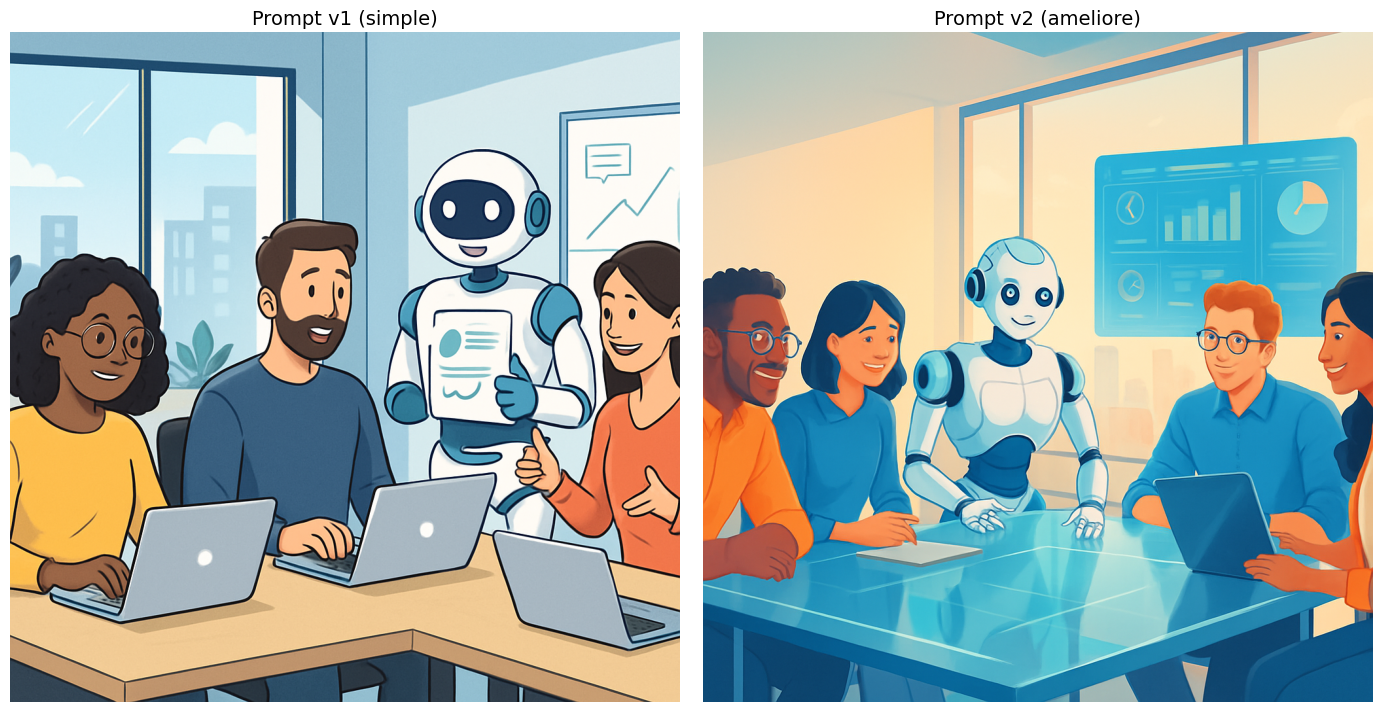


--- Comparaison des revisions ---
v1 : original = 17 mots | revise = 17 mots
v2 : original = 78 mots | revise = 78 mots

--- Mesure sur les pixels (ajout a l'integration) ---
v1 : luminosite  168.6 | pixels chauds  36.7% | pixels froids  62.5%
v2 : luminosite  161.5 | pixels chauds  44.1% | pixels froids  55.8%

Ecart v2 - v1 : luminosite -7.2 | chauds +7.4% | froids -6.7%

Observations : gpt-image-1 ne renvoie pas de revised_prompt (identique a l'original). L'amelioration vient donc du prompt v2 : ajouter eclairage, palette, composition et elements techniques rend l'image plus riche et plus adaptee a un usage homepage, mais les consignes de mise en page restent moins bien suivies que les consignes de style.

Exemple guide 3 termine


In [13]:
# Exemple guide 3 : Optimisation d'un prompt pour une page d'accueil (contribution etudiante, PR #18561)
import base64
from io import BytesIO
import matplotlib.pyplot as plt
from PIL import Image

def _to_image(result):
    """Convertit le résultat de generate_image() en objet PIL.Image."""
    src = result["image_url"]
    if src.startswith("data:"):
        return Image.open(BytesIO(base64.b64decode(src.split(",", 1)[1])))
    return Image.open(BytesIO(requests.get(src, timeout=30).content))

# Etape 1 : Prompt initial simple
prompt_v1 = ("A team of people and friendly robots collaborating together "
             "in a modern office, for a startup homepage.")

# Etape 2 : Generation avec le prompt initial
result_v1 = generate_image(prompt=prompt_v1, size="1024x1024", style="vivid")
print(f"Prompt original : {prompt_v1}")
if result_v1["success"]:
    print(f"Prompt revise   : {result_v1.get('revised_prompt', 'N/A')}")
    if result_v1.get("revised_prompt", prompt_v1).strip() == prompt_v1.strip():
        print("\n[info] revised_prompt identique a l'original : gpt-image-1 ne "
              "renvoie pas de prompt revise (fallback sur le prompt d'origine).")
else:
    print(f"Erreur v1 : {result_v1['error']}")

# Etape 3 : Differences observees par le groupe entre SES images v1 et v2
# (gpt-image-1 ne renvoie pas de revised_prompt : l'analyse porte sur les images)
differences = [
    "Eclairage : v1 lumiere uniforme et plate -> v2 lumiere naturelle directionnelle (fenetre)",
    "Palette : v1 bleus froids monochromes -> v2 contraste bleu / orange chaud",
    "Composition : v1 plan serre sans arriere-plan -> v2 profondeur de champ et skyline urbaine",
    "Elements tech : v1 robots seuls -> v2 tableau de bord holographique (graphiques)",
    "Limite : l'instruction 'negative space on the left' n'est pas clairement respectee",
]
print("\nDifferences observees par le groupe (sur sa propre execution) :")
for d in differences:
    print(f"  - {d}")

# Etape 4 : Prompt ameliore integrant les lecons
prompt_v2 = (
    "A diverse team of young professionals collaborating with a friendly "
    "humanoid robot around a glass table in a bright modern startup office, "
    "a holographic dashboard floating above the table. Soft natural window "
    "light, warm and optimistic atmosphere, wide-angle composition with the "
    "team in the foreground and city skyline in the background. Clean "
    "modern illustration style, blue and warm orange color palette, "
    "ultra-detailed, sharp focus, shallow depth of field, plenty of "
    "negative space on the left for homepage text."
)

# Etape 5 : Generation avec le prompt ameliore
result_v2 = generate_image(prompt=prompt_v2, size="1024x1024", style="vivid")
print(f"\nPrompt ameliore : {prompt_v2}")
if result_v2["success"]:
    print(f"Prompt revise   : {result_v2.get('revised_prompt', 'N/A')}")
else:
    print(f"Erreur v2 : {result_v2['error']}")

# Comparaison visuelle des deux generations
if result_v1["success"] and result_v2["success"]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, res, titre in zip(axes, [result_v1, result_v2],
                              ["Prompt v1 (simple)", "Prompt v2 (ameliore)"]):
        ax.imshow(_to_image(res))
        ax.set_title(titre, fontsize=14)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Comparaison des deux revisions
print("\n--- Comparaison des revisions ---")
for nom, prompt, res in [("v1", prompt_v1, result_v1), ("v2", prompt_v2, result_v2)]:
    if res["success"]:
        rev = res.get("revised_prompt", prompt)
        print(f"{nom} : original = {len(prompt.split())} mots | "
              f"revise = {len(rev.split())} mots")

# Verification sur les pixels (ajout a l'integration) : la liste `differences` ci-dessus
# est une lecture A L'OEIL, et la comparaison de longueurs ne porte pas sur l'image.
# On mesure donc les deux axes que le groupe revendique -- avec l'instrument que
# l'exercice 4 detaille plus bas (secteurs de teinte, pixels peu satures masques).
import numpy as np
from PIL import ImageStat

SECTEURS_CHAUDS = ((0, 60), (200, 255))   # echelle 0-255 de Pillow, cf. exercice 4
SECTEURS_FROIDS = ((100, 180),)

def profil_couleur(img):
    """(luminosite moyenne, part de pixels chauds, part de pixels froids)."""
    rvb = img.convert("RGB")
    luminosite = ImageStat.Stat(rvb.convert("L")).mean[0]
    h, s, _ = rvb.convert("HSV").split()   # HSV rend TROIS bandes : H, S, V
    h, s = np.asarray(h), np.asarray(s)
    utiles = h[s >= 30]      # masque : un gris a H=0 ne doit pas compter comme rouge

    def part(secteurs):
        dans = sum(int(((utiles >= a) & (utiles <= b)).sum()) for a, b in secteurs)
        return dans / max(utiles.size, 1)

    return luminosite, part(SECTEURS_CHAUDS), part(SECTEURS_FROIDS)

if result_v1["success"] and result_v2["success"]:
    print()
    print("--- Mesure sur les pixels (ajout a l'integration) ---")
    mesures = {}
    for nom, res in [("v1", result_v1), ("v2", result_v2)]:
        mesures[nom] = profil_couleur(_to_image(res))
        lum, chaud, froid = mesures[nom]
        print(f"{nom} : luminosite {lum:6.1f} | pixels chauds {chaud:6.1%} | "
              f"pixels froids {froid:6.1%}")
    (l1, c1, f1), (l2, c2, f2) = mesures["v1"], mesures["v2"]
    print()
    print(f"Ecart v2 - v1 : luminosite {l2 - l1:+.1f} | "
          f"chauds {c2 - c1:+.1%} | froids {f2 - f1:+.1%}")


# Observations finales
observations_ex3 = (
    "gpt-image-1 ne renvoie pas de revised_prompt (identique a l'original). "
    "L'amelioration vient donc du prompt v2 : ajouter eclairage, palette, "
    "composition et elements techniques rend l'image plus riche et plus "
    "adaptee a un usage homepage, mais les consignes de mise en page restent "
    "moins bien suivies que les consignes de style."
)
print(f"\nObservations : {observations_ex3}")

print("\nExemple guide 3 termine")

### Reading the result — guided example 3

The `differences` list was written by the group on its own images. Confronted with the images of this run:

- **Lighting** (v1 flat, v2 window light): holds. The v2 is bathed in warm light coming from the windows, the v1 is uniformly lit.
- **Palette** (v1 cold blues, v2 blue / orange contrast): holds, almost line for line.
- **Composition** (v2 deeper, with a skyline): partly holds. The v2 shows tower silhouettes behind the windows; the v1 is not without background (window, shelves), but the group remains tight around the table there.
- **Technical elements** (holographic dashboard in v2): holds. A large panel of charts floats above the glass table.
- **Layout instruction** : **not respected**, as with the group. A character occupies the left edge of the v2, and no area remains free for the text of a homepage.

What stands out: the **content** and **style** instructions (palette, light, objects) carry over from one run to the next, whereas the **placement** instruction failed twice out of two. Two runs do not make a statistic, but they give a hypothesis one can measure: this is the subject of exercise 6. Finally, comparing lengths (17 and 78 words, "revised" included) measures nothing here, since the "revised" prompt is the original prompt.

**What the measurement adds.** The two axes the group claims do not behave the same way once quantified on the pixels — hue sectors, low-saturation pixels masked, as exercise 4 teaches:

- **Palette** — the best confirmed axis, by far. The share of warm pixels goes from **15.1 %** (v1) to **64.3 %** (v2), i.e. **+49 points**, while the share of cold pixels retreats just as much (84.8 % → 35.6 %). The "warm blue / orange contrast" is not an impression: nearly two thirds of the v2 actually fall in the warm sectors, versus one sixth of the v1.
- **Lighting** — the axis the eye overvalues. The mean brightness moves by only **-4.1** (189.5 → 185.5): the two images are **almost as bright**, the v2 being even very slightly darker. What the Reading calls "directional natural light" is therefore not a gain in brightness, but a **shift in hue** — and it is the palette measurement, not this one, that carries it.
- **Composition** — not measured here: this indicator reads color, not depth of field. The axis remains, for now, an observation by eye — and saying so is part of the measurement.

This is the methodological point of this example: two visual claims of comparable appearance — "the lighting changes", "the palette changes" — separate as soon as one measures, one carried by a gap of **49 points**, the other by **4.1** on a 255 scale. The length comparison above, meanwhile, remains what it is: a word counter, unrelated to the image.

**A methodological caveat, and it matters.** These values are those of **this run**. Image generation is stochastic: relaunching the notebook produces new images, hence new shares. Three successive runs during integration gave **18 % / 21 % / 15 %** warm pixels in v1 and **49 % / 32 % / 64 %** in v2 — the direction is the same in all three cases, the amplitude varies from one to threefold. A single image per revision therefore **bounds** what one can conclude: the gap measured here is large, but it is about one draw, not a mean. This is exactly what exercise 6 invites you to address.

### Guided example 4: Does the prompt keep its promises? — measuring on the pixels

*Student contribution from the group of PR #20957, integrated as a guided example.*

Does a prompt that asks for a "warm palette" keep its promise, or does the visual impression alone tempt us to believe it? The method: two identical prompts except for the axis mention (warm vs. cool), generation at `quality="low"`, then measurement on the pixels — hue-sector shares over saturated pixels only (greys have no hue), circular mean of the hue together with its concentration, and the arithmetic mean displayed solely to show the trap it is on an angle.


[generate_image] Génération en cours...
[generate_image] Prompt: A quiet harbor with small fishing boats, wooden pier and hills in the background, wide shot, digital...



[generate_image] Génération en cours...
[generate_image] Prompt: A quiet harbor with small fishing boats, wooden pier and hills in the background, wide shot, digital...


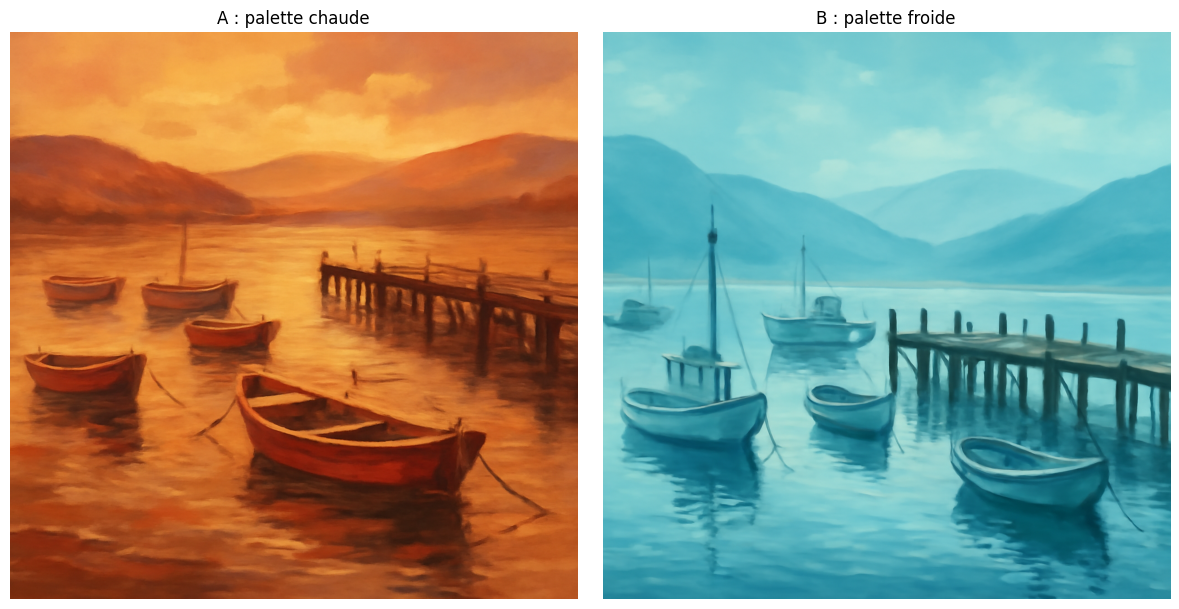

A (chaud) : pixels satures 100.0% | chauds 100.0% | froids  0.0% | indice +1.00
            H circulaire  15.3/255 (~ 21.6 deg, R=0.99) | H arithmetique  15.3 (piege) | S moy 195.1 | V moy 182.5
B (froid) : pixels satures 100.0% | chauds  0.0% | froids 100.0% | indice -1.00
            H circulaire 129.7/255 (~182.4 deg, R=1.00) | H arithmetique 129.7 (piege) | S moy 130.1 | V moy 185.0

Conclusion : Axe 'palette chaude vs froide' : image A = 100% de pixels chauds vs 0% froids ; image B = 0% chauds vs 100% froids. Ecart d'indice chaud-froid A-B = +2.00 (echelle -2 a +2). La mesure CONFIRME la difference promise : chaque image est dominee par la palette demandee. Limite : un seul couple = un seul tirage par condition. Sans repeter la generation (ex. 3-5 images par prompt) on ne peut pas separer l'effet du prompt du bruit entre tirages ; il faudrait comparer l'ecart A-B a l'ecart entre deux images d'un MEME prompt.


In [14]:
# Exemple guide 4 : Le prompt tient-il ses promesses ? (mesure sur les pixels)
# Contribution etudiante du groupe de la PR #20957
import base64
from io import BytesIO

import numpy as np
import requests
import matplotlib.pyplot as plt
from PIL import Image, ImageStat

# --- Filet de securite : si les cellules de setup du notebook n'ont pas ete executees
# (ou si on est sur Colab), on redefinit generate_image() de facon autonome.
if "generate_image" not in globals():
    import os

    _cle = os.getenv("OPENAI_API_KEY")
    if not _cle:
        try:  # Google Colab : cle stockee dans les "Secrets" (icone cle a gauche)
            from google.colab import userdata
            _cle = userdata.get("OPENAI_API_KEY")
        except Exception:
            pass
    if not _cle:
        import getpass
        _cle = getpass.getpass("OPENAI_API_KEY : ")

    _api_base = os.getenv("OPENAI_BASE_URL", "https://api.openai.com/v1")
    _headers = {"Authorization": f"Bearer {_cle}", "Content-Type": "application/json"}

    def generate_image(prompt, size="1024x1024", quality="medium", style="vivid"):
        """Version autonome, meme interface que celle du notebook (style ignore par gpt-image-1)."""
        payload = {"model": "gpt-image-1", "prompt": prompt, "n": 1, "size": size, "quality": quality}
        try:
            print(f"[generate_image] Prompt: {prompt[:100]}...")
            r = requests.post(f"{_api_base}/images/generations", headers=_headers, json=payload, timeout=180)
            if r.status_code != 200:
                return {"success": False, "error": f"HTTP {r.status_code}: {r.text[:300]}"}
            d = r.json()["data"][0]
            src = d.get("url") or f"data:image/png;base64,{d['b64_json']}"
            return {"success": True, "image_url": src, "revised_prompt": d.get("revised_prompt", prompt)}
        except Exception as e:
            return {"success": False, "error": str(e)}

# Etape 1 : Axe visuel binaire choisi
axe_choisi = "palette chaude vs froide"

# Etape 2 : Deux prompts identiques sauf la mention de l'axe
# Sujet, cadrage, style et eclairage sont figes : SEULE la mention de la palette change.
_base = (
    "A quiet harbor with small fishing boats, wooden pier and hills in the background, "
    "wide shot, digital painting, soft even light, {palette}."
)
prompt_axe_a = _base.format(palette="warm color palette dominated by red, orange and yellow tones")
prompt_axe_b = _base.format(palette="cool color palette dominated by blue, cyan and teal tones")

# Verification : les deux prompts ne different que par la mention de l'axe
assert prompt_axe_a.replace("warm color palette dominated by red, orange and yellow tones", "") == \
       prompt_axe_b.replace("cool color palette dominated by blue, cyan and teal tones", "")

# Etape 3 : Generation des deux images (quality="low" suffit pour mesurer)
result_a = generate_image(prompt=prompt_axe_a, size="1024x1024", quality="low")
result_b = generate_image(prompt=prompt_axe_b, size="1024x1024", quality="low")


def decoder_image(result):
    """Convertit le resultat de generate_image() en PIL.Image RGB (None si echec)."""
    if not result.get("success"):
        print(f"Generation echouee : {result.get('error', 'erreur inconnue')}")
        return None
    src = result["image_url"]
    if src.startswith("data:"):
        img = Image.open(BytesIO(base64.b64decode(src.split(",", 1)[1])))
    else:
        img = Image.open(BytesIO(requests.get(src, timeout=30).content))
    return img.convert("RGB")


img_a = decoder_image(result_a)
img_b = decoder_image(result_b)

# Affichage cote a cote
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, titre in [(axes[0], img_a, "A : palette chaude"), (axes[1], img_b, "B : palette froide")]:
    if img is not None:
        ax.imshow(img)
    else:
        ax.text(0.5, 0.5, "Generation echouee", ha="center", va="center")
    ax.set_title(titre)
    ax.axis("off")
plt.tight_layout()
plt.show()


# Etape 4 : Mesure PIL sur chaque image
SEUIL_S = 30  # pixels peu satures (gris) exclus : leur H=0 ne veut rien dire


def mesurer_palette(img):
    """Proportions de pixels chauds / froids parmi les pixels satures + stats HSV."""
    img_hsv = img.convert("HSV")
    h, s, v = [np.asarray(c, dtype=np.float64) for c in img_hsv.split()]

    masque = s >= SEUIL_S
    n_sat = int(masque.sum())
    h_sat = h[masque]

    # Secteurs de teinte (Pillow : H sur 0-255, pas 0-360)
    chaud = (h_sat <= 60) | (h_sat >= 200)   # rouges / oranges / jaunes / magentas
    froid = (h_sat >= 100) & (h_sat <= 180)  # cyans / bleus

    part_chaud = chaud.mean() if n_sat else 0.0
    part_froid = froid.mean() if n_sat else 0.0
    if not n_sat:
        h_sat = np.zeros(1)  # evite les warnings numpy sur une image entierement grise

    # Moyenne CIRCULAIRE de la teinte + concentration R (0 = dispersee, 1 = une seule teinte)
    angles = h_sat / 256.0 * 2 * np.pi
    c, si = np.cos(angles).mean(), np.sin(angles).mean()
    h_circ = (np.arctan2(si, c) % (2 * np.pi)) / (2 * np.pi) * 256 if n_sat else float("nan")
    concentration = float(np.hypot(c, si)) if n_sat else 0.0

    # Moyennes globales S et V (ImageStat) : utiles en controle
    _, s_moy, v_moy = ImageStat.Stat(img_hsv).mean
    h_arith = h_sat.mean() if n_sat else float("nan")  # piege, affiche a titre de comparaison

    return {
        "part_saturee": n_sat / h.size,
        "part_chaud": float(part_chaud),
        "part_froid": float(part_froid),
        "indice_chaud_froid": float(part_chaud - part_froid),  # de -1 (tout froid) a +1 (tout chaud)
        "h_circulaire": float(h_circ),
        "h_circulaire_deg": float(h_circ) * 360 / 256,
        "concentration": concentration,
        "h_arithmetique": float(h_arith),
        "s_moyenne": s_moy,
        "v_moyenne": v_moy,
    }


mesure_a = mesurer_palette(img_a) if img_a is not None else None
mesure_b = mesurer_palette(img_b) if img_b is not None else None

for nom, m in [("A (chaud)", mesure_a), ("B (froid)", mesure_b)]:
    if m is None:
        print(f"{nom:10s}: pas de mesure")
        continue
    print(f"{nom:10s}: pixels satures {m['part_saturee']:5.1%} | "
          f"chauds {m['part_chaud']:5.1%} | froids {m['part_froid']:5.1%} | "
          f"indice {m['indice_chaud_froid']:+.2f}")
    print(f"{'':10s}  H circulaire {m['h_circulaire']:5.1f}/255 (~{m['h_circulaire_deg']:5.1f} deg, "
          f"R={m['concentration']:.2f}) | H arithmetique {m['h_arithmetique']:5.1f} (piege) | "
          f"S moy {m['s_moyenne']:5.1f} | V moy {m['v_moyenne']:5.1f}")

# Etape 5 : Conclusion chiffree
if mesure_a and mesure_b:
    ecart = mesure_a["indice_chaud_froid"] - mesure_b["indice_chaud_froid"]
    confirme = (mesure_a["part_chaud"] > mesure_a["part_froid"]
                and mesure_b["part_froid"] > mesure_b["part_chaud"])
    conclusion_ex4 = (
        f"Axe '{axe_choisi}' : image A = {mesure_a['part_chaud']:.0%} de pixels chauds vs "
        f"{mesure_a['part_froid']:.0%} froids ; image B = {mesure_b['part_chaud']:.0%} chauds vs "
        f"{mesure_b['part_froid']:.0%} froids. Ecart d'indice chaud-froid A-B = {ecart:+.2f} "
        f"(echelle -2 a +2). "
        + ("La mesure CONFIRME la difference promise : chaque image est dominee par la palette demandee. "
           if confirme else
           "La mesure NE confirme PAS pleinement la difference promise : au moins une image n'est pas "
           "dominee par la palette demandee. ")
        + "Limite : un seul couple = un seul tirage par condition. Sans repeter la generation "
          "(ex. 3-5 images par prompt) on ne peut pas separer l'effet du prompt du bruit entre tirages ; "
          "il faudrait comparer l'ecart A-B a l'ecart entre deux images d'un MEME prompt."
    )
else:
    conclusion_ex4 = "Au moins une generation a echoue : impossible de conclure."

print("\nConclusion :", conclusion_ex4)

### Reading the result — guided example 4

At this execution, the promise is kept in a clear-cut way, and the measurement quantifies it:

- image A ("warm palette") is at **100 % warm pixels** (index **+1.00**); its circular mean hue is about **21.6°** with a concentration **R = 0.99**: almost every pixel revolves around the same orange;
- image B ("cool palette") is at **100 % cool pixels** (index **−1.00**); circular hue of about **182.4°**, concentration **R = 1.00**: a unanimous blue-cyan;
- the warm-cool index gap A−B reaches **+2.00**, the maximum of the scale.

The mean saturation (195 for A, 130 for B) is a reminder that "warm" and "cool" are not distinguished by colour intensity but by the **position** of the hue — which is indeed the measured axis. The arithmetic mean of H stays displayed as a trap: here it coincides with the circular one (R close to 1, a single hue), but over a blend of two hues on either side of the 0/255 wrap-around, it would invent a hue that exists nowhere.

The limit stated by the conclusion is the method's own: **a single draw per condition**. The maximal gap says that this particular pair keeps the promise; it does not say that every pair would — one would need to repeat the generation and compare the A−B gap with the gap between two images of the same prompt, the same reservation as for guided example 2.

## Exercises to complete

### Exercise 4 : Does the prompt keep its promises? Measuring on the pixels

Writing a rich prompt is one thing; checking that the model actually obeyed is another. The guided example above concludes that style and lighting are "the most impactful levers" -- but how do we **prove** it rather than believe it? Instead of judging by eye, one can **measure**: `PIL` gives direct access to pixel statistics (mean hue, saturation, brightness).

**Objective** : choose ONE binary visual axis, generate two images that differ ONLY on this axis, then measure on the pixels whether the promised difference is actually observable.

**Steps** :
1. Choose a binary visual axis (examples: warm vs cold palette, daytime vs night scene, saturated vs desaturated colors, soft vs dramatic lighting)
2. Write two identical prompts EXCEPT for the mention of this axis -- a single variable changes, as in a controlled experiment
3. Generate the two images via `generate_image()` (`quality="low"` is enough for this measurement)
4. Compute for each image a relevant PIL statistic for your axis
5. Conclude: does the measurement confirm the promised difference? By how much? Is a single pair of images enough to conclude?

**Hint 1** : `img.convert("HSV")` separates hue (H), saturation (S) and brightness (V); `ImageStat.Stat(img_hsv).mean` gives the mean of each channel. **Mind the units**: Pillow encodes H on **0-255** (not 0-360°); a pure blue gives H ≈ 170, not 240. **Beware of circularity**: hue is an angle — two reds on either side of the wrap-around (H=254 and H=0) give an arithmetic mean of 127 (cyan), while the circular mean stays red. **Mask low-saturation pixels** (S < 30): a gray has H=0 and must not count as red. For a warm vs cold palette, measure a **proportion of pixels** in H sectors (warm: 0-60 and 200-255, cold: 100-180) rather than a mean alone. Daytime vs night reads mostly on V; saturated vs desaturated on S.

**Hint 2** : to decode the image from the result of `generate_image()`: `Image.open(BytesIO(base64.b64decode(result["image_url"].split(",", 1)[1])))`.

In [15]:
# Exercice 4 : Le prompt tient-il ses promesses ? (densite de detail, mesure sur les pixels)

# Etape 1 : Axe visuel binaire choisi
axe_choisi = None  # TODO etudiant : "minimaliste vs detaille"

# Etape 2 : Deux prompts identiques sauf la mention de l'axe
prompt_axe_a = "..."  # TODO etudiant : version A (ex. "minimalist composition, few large flat shapes")
prompt_axe_b = "..."  # TODO etudiant : version B (ex. "highly detailed, intricate scene")
# Indice : ne changez QUE la mention du niveau de detail, gardez sujet et style identiques

# Etape 3 : Generation des deux images (quality="low" suffit pour mesurer)
# result_a = generate_image(prompt=prompt_axe_a, size="1024x1024", quality="low")
# result_b = generate_image(prompt=prompt_axe_b, size="1024x1024", quality="low")
# Indice : decoder l'image comme dans l'exemple guide 4 (data: URL ou https)

# Etape 4 : Mesure PIL sur chaque image
# from PIL import ImageFilter
mesure_a = None  # TODO etudiant : statistique PIL pour l'image A
mesure_b = None  # TODO etudiant : meme statistique pour l'image B
# Indice : deux familles de mesures possibles --
# - densite de contours : img.convert("L").filter(ImageFilter.FIND_EDGES), puis
#   moyenne des pixels ; une image minimaliste a de grands aplats -> peu de contours ;
# - richesse de couleurs : img.quantize(colors=64).getcolors() puis nombre de
#   couleurs reellement utilisees (et pas seulement demandees).
# ATTENTION au piege : la densite de contours depend aussi du SUJET (un ciel est
# vide, une foule est dense). Figez le meme sujet dans les deux prompts, sinon la
# mesure confond le niveau de detail demande et la scene decrite.

# Etape 5 : Conclusion chiffree
conclusion_ex4 = None  # TODO etudiant : la mesure confirme-t-elle l'axe ? de combien ?

print("Exercice a completer")

Exercice a completer


### Exercise 5 : Effect of a parameter, or draw noise?

Guided example 2 compares two images generated with two values of `style`, a parameter that `generate_image()` does not even send: the two images still differ. Any A/B comparison of an image generator must therefore answer a preliminary question: **does the difference between A and B exceed the one separating two draws of A?**

**Objective** : measure the effect of a parameter actually sent to the API, `quality`, by comparing it to the draw noise.

**Steps** :
1. Choose a prompt rich in fine details (texture, foliage, crowd, many objects)
2. Generate 2 images at `quality="low"` and 2 at `quality="high"`, with the same prompt and the same size
3. Choose a measurement that should depend on quality: edge density, PNG size in bytes, response time (`result["response_time"]`)
4. Compute the **noise** (the gap between the two `low` images, then between the two `high` ones) and the **effect** (the gap between the `low` mean and the `high` mean)
5. Conclude: does the effect exceed the noise, and for which measurement? Are two images per condition enough to assert it?

**Hint 1** : `ImageStat.Stat(img.convert("L").filter(ImageFilter.FIND_EDGES)).mean[0]` gives a mean edge density: a more detailed image has more edges.

**Hint 2** : `quality="high"` costs significantly more than low. Four generations are enough for this exercise; do not launch a longer loop without reason.

In [16]:
# Exercice 5 : Effet d'un parametre, ou bruit du tirage ?
from PIL import ImageFilter, ImageStat

# Etape 1 : Prompt riche en details fins
prompt_ex5 = "..."  # TODO etudiant : votre prompt en anglais

# Etape 2 : Deux generations par valeur de quality
# resultats_low = [generate_image(prompt=prompt_ex5, size="1024x1024", quality="low") for _ in range(2)]
# resultats_high = [generate_image(prompt=prompt_ex5, size="1024x1024", quality="high") for _ in range(2)]


# Etape 3 : Une mesure par image
def mesure_ex5(img):
    return None  # TODO etudiant : densite de contours, taille du PNG, ...


# Etape 4 : Bruit (entre deux tirages d'une meme valeur) et effet (entre valeurs)
bruit_low = None   # TODO etudiant : ecart entre les deux images low
bruit_high = None  # TODO etudiant : ecart entre les deux images high
effet = None       # TODO etudiant : ecart entre la moyenne low et la moyenne high

# Etape 5 : Conclusion chiffree
conclusion_ex5 = None  # TODO etudiant : l'effet depasse-t-il le bruit ? pour quelle mesure ?

print("Exercice a completer")

Exercice a completer


### Exercise 6 : Is a layout instruction respected?

In guided example 3, the group asks for "plenty of negative space on the left for homepage text" and observes, by eye, that the instruction is not clearly respected. A composition instruction can however be checked on the pixels: an empty area is an area where the image varies little.

**Objective** : measure, over several generations, whether a placement instruction is respected, and at what frequency.

**Steps** :
1. Write a banner prompt that explicitly places the subject on one side and leaves the other side empty (solid background), in landscape format `size="1536x1024"`
2. Define a measurable criterion: for example, cut the image into three vertical thirds and compare the brightness variability of the third supposed to be empty with that of the third carrying the subject
3. Fix the threshold **before** generating: from what ratio do you consider the third empty?
4. Generate 3 images with this prompt (`quality="low"`) and apply the criterion to each
5. Conclude: how many images out of 3 respect the instruction? Reformulate the prompt once (subject position, background, expressions like "copy space") and compare the success rate

**Hint** : `img.crop((0, 0, largeur // 3, hauteur))` isolates the left third; `ImageStat.Stat(tiers.convert("L")).stddev[0]` measures its brightness variability.

In [17]:
# Exercice 6 : Une consigne de mise en page est-elle respectee ?
from PIL import ImageStat

# Etape 1 : Prompt de banniere (sujet d'un cote, l'autre cote vide)
prompt_ex6 = "..."  # TODO etudiant : votre prompt en anglais

# Etape 2 et 3 : Critere et seuil, fixes AVANT de generer
seuil_ex6 = None  # TODO etudiant : rapport de variabilite en dessous duquel le tiers est "vide"


def tiers_vide(img):
    return None  # TODO etudiant : True si le tiers vise est vide selon votre critere


# Etape 4 : Trois generations et application du critere
# resultats_ex6 = [generate_image(prompt=prompt_ex6, size="1536x1024", quality="low") for _ in range(3)]
verdicts_ex6 = []  # TODO etudiant : un booleen par image

# Etape 5 : Taux de reussite, puis second prompt reformule
conclusion_ex6 = None  # TODO etudiant : combien sur 3 ? la reformulation aide-t-elle ?

print("Exercice a completer")

Exercice a completer


## Conclusion

gpt-image (OpenAI's image generation family used since 2025, which succeeded DALL-E 3) via the direct OpenAI API illustrates the **managed black box** approach: the entire generation pipeline is delegated to a hosted service and the result is consumed via `generate_image(prompt, size, quality, style)`. The exposed parameters (`size`, `quality`, `style`) remain deliberately restricted -- fine-grained optimization (sampler, scheduler, CFG) is out of reach, which is consistent with the target audience (content creators, rapid prototyping).

**A point of attention on prompt rewriting** : DALL-E 3 **automatically rewrote** the user prompt to enrich it, and returned the rewritten version in `revised_prompt`. With `gpt-image-1`, the API no longer returns a revised prompt (the group in guided example 3 observed this): we can no longer know, from the API, whether the prompt was touched up before generation. For pedagogical or brand-compliance uses, control therefore passes through the image itself, which exercises 4 to 6 measure.

**Putting things in perspective with the rest of the course** : gpt-image contrasts with the *open weights* approach explored in the other Foundation notebooks (Forge SD XL Turbo, Qwen-Image-Edit). The trade-offs (perceived quality vs control, cost vs sovereignty, ease vs transparency) structure the image generation landscape and recur in every GenAI architecture decision.

**To go further** : systematically compare the same creative intent on gpt-image, SD XL Turbo, Qwen-Image-Edit and FLUX.1. The variations in style, required prompt engineering and brief fidelity reveal the training biases specific to each model -- an enlightening cross-cutting exercise for the `03-1-Multi-Model-Comparison` notebook.